# 1. Load Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import euclidean_distances
from sklearn.manifold import MDS
from sklearn.isotonic import IsotonicRegression

In [ ]:
from google.colab import files
files.upload()

Saving electric_vehicles_spec_2025.csv to electric_vehicles_spec_2025.csv


{'electric_vehicles_spec_2025.csv': b'brand,model,top_speed_kmh,battery_capacity_kWh,battery_type,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,fast_charging_power_kw_dc,fast_charge_port,towing_capacity_kg,cargo_volume_l,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,source_url\nAbarth,500e Convertible,155,37.8,Lithium-ion,192,235,156,225,7.0,67,CCS,0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1904/Abarth-500e-Convertible\nAbarth,500e Hatchback,155,37.8,Lithium-ion,192,235,149,225,7.0,67,CCS,0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1903/Abarth-500e-Hatchback\nAbarth,600e Scorpionissima,200,50.8,Lithium-ion,102,345,158,280,5.9,79,CCS,0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3057/Abarth-600e-Scorpionissima\nAbarth,600e Turismo,200,50.8,Lithium-ion,102,345,158,280,6.2,79,CCS,0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.or

In [ ]:
df = pd.read_csv('electric_vehicles_spec_2025.csv')
df

,brand,model,top_speed_kmh,battery_capacity_kWh,battery_type,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,...,towing_capacity_kg,cargo_volume_l,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,source_url
0,Abarth,500e Convertible,155,37.8,Lithium-ion,192.0,235.0,156,225,7.0,...,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1904/Abarth-500e-C...
1,Abarth,500e Hatchback,155,37.8,Lithium-ion,192.0,235.0,149,225,7.0,...,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1903/Abarth-500e-H...
2,Abarth,600e Scorpionissima,200,50.8,Lithium-ion,102.0,345.0,158,280,5.9,...,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3057/Abarth-600e-S...
3,Abarth,600e Turismo,200,50.8,Lithium-ion,102.0,345.0,158,280,6.2,...,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3056/Abarth-600e-T...
4,Aiways,U5,150,60.0,Lithium-ion,NaN,310.0,156,315,7.5,...,NaN,496,5,FWD,JC - Medium,4680,1865,1700,SUV,https://ev-database.org/car/1678/Aiways-U5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
473,Zeekr,7X Premium RWD,210,71.0,Lithium-ion,NaN,440.0,148,365,6.0,...,2000.0,539,5,RWD,JD - Large,4787,1930,1650,SUV,https://ev-database.org/car/3081/Zeekr-7X-Prem...
474,Zeekr,X Core RWD (MY25),190,49.0,Lithium-ion,NaN,343.0,148,265,5.9,...,1600.0,362,5,RWD,JB - Compact,4432,1836,1566,SUV,https://ev-database.org/car/3197/Zeekr-X-Core-RWD
475,Zeekr,X Long Range RWD (MY25),190,65.0,Lithium-ion,NaN,343.0,146,360,5.6,...,1600.0,362,5,RWD,JB - Compact,4432,1836,1566,SUV,https://ev-database.org/car/3198/Zeekr-X-Long-...
476,Zeekr,X Privilege AWD (MY25),190,65.0,Lithium-ion,NaN,543.0,153,350,3.8,...,1600.0,362,5,AWD,JB - Compact,4432,1836,1566,SUV,https://ev-database.org/car/3199/Zeekr-X-Privi...


# 2. Preprocessing Data

In [ ]:
# Menentukan kolom numerik
numeric_cols = ['top_speed_kmh', 'battery_capacity_kWh', 'torque_nm', 'efficiency_wh_per_km', 'range_km', 'fast_charging_power_kw_dc', 'cargo_volume_l', 'length_mm', 'width_mm', 'height_mm']

In [ ]:
# Membuat label unik untuk tiap mobil
df['car_label'] = df['brand'].astype(str) + ' ' + df['model'].astype(str)
selected_cols = ['car_label', 'brand', 'car_body_type'] + numeric_cols
df_sub = df[selected_cols].copy()
df_sub

,car_label,brand,car_body_type,top_speed_kmh,battery_capacity_kWh,torque_nm,efficiency_wh_per_km,range_km,fast_charging_power_kw_dc,cargo_volume_l,length_mm,width_mm,height_mm
0,Abarth 500e Convertible,Abarth,Hatchback,155,37.8,235.0,156,225,67.0,185,3673,1683,1518
1,Abarth 500e Hatchback,Abarth,Hatchback,155,37.8,235.0,149,225,67.0,185,3673,1683,1518
2,Abarth 600e Scorpionissima,Abarth,SUV,200,50.8,345.0,158,280,79.0,360,4187,1779,1557
3,Abarth 600e Turismo,Abarth,SUV,200,50.8,345.0,158,280,79.0,360,4187,1779,1557
4,Aiways U5,Aiways,SUV,150,60.0,310.0,156,315,78.0,496,4680,1865,1700
...,...,...,...,...,...,...,...,...,...,...,...,...,...
473,Zeekr 7X Premium RWD,Zeekr,SUV,210,71.0,440.0,148,365,240.0,539,4787,1930,1650
474,Zeekr X Core RWD (MY25),Zeekr,SUV,190,49.0,343.0,148,265,70.0,362,4432,1836,1566
475,Zeekr X Long Range RWD (MY25),Zeekr,SUV,190,65.0,343.0,146,360,114.0,362,4432,1836,1566
476,Zeekr X Privilege AWD (MY25),Zeekr,SUV,190,65.0,543.0,153,350,114.0,362,4432,1836,1566


In [ ]:
# Cek Missing Value
missing_summary = pd.DataFrame({
    'Jumlah_Missing': df_sub.isnull().sum(),
    'Persentase_Missing (%)': (df_sub.isnull().sum() / len(df_sub) * 100).round(2)
})
print(missing_summary)
print(f"Total baris awal: {len(df_sub)} | Total baris duplikat label: {df_sub.duplicated(subset=['car_label']).sum()}")

                           Jumlah_Missing  Persentase_Missing (%)
car_label                               0                    0.00
brand                                   0                    0.00
car_body_type                           0                    0.00
top_speed_kmh                           0                    0.00
battery_capacity_kWh                    0                    0.00
torque_nm                               7                    1.46
efficiency_wh_per_km                    0                    0.00
range_km                                0                    0.00
fast_charging_power_kw_dc               1                    0.21
cargo_volume_l                          1                    0.21
length_mm                               0                    0.00
width_mm                                0                    0.00
height_mm                               0                    0.00
Total baris awal: 478 | Total baris duplikat label: 0


In [ ]:
# Pembersihan Data
for col in numeric_cols:
    df_sub[col] = pd.to_numeric(df_sub[col], errors='coerce')

df_clean = df_sub.dropna().drop_duplicates(subset=['car_label']).reset_index(drop=True)

print(f"\n=== STATUS SETELAH PEMBERSIHAN ===")
print(f"Total baris bersih siap analisis : {len(df_clean)} observasi")
print(f"Sisa missing value               : {df_clean.isnull().sum().sum()} (Bersih)")


=== STATUS SETELAH PEMBERSIHAN ===
Total baris bersih siap analisis : 466 observasi
Sisa missing value               : 0 (Bersih)


In [ ]:
# Ambil 40 sampel model brand dari model EV populer
target_brands = ['Tesla', 'Hyundai', 'Kia', 'BYD', 'BMW', 'Mercedes-Benz', 'Audi', 'Porsche', 'Volkswagen', 'Volvo']
df_sample = df_clean[df_clean['brand'].isin(target_brands)].sample(n=40, random_state=42).reset_index(drop=True)

In [ ]:
# Statistika Deskriptif
summary = df.describe()
summary.round(2)

,top_speed_kmh,battery_capacity_kWh,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,fast_charging_power_kw_dc,towing_capacity_kg,seats,length_mm,width_mm,height_mm
count,478.00,478.00,276.00,471.00,478.00,478.00,478.00,477.00,452.00,478.00,478.00,478.00,478.00
mean,185.49,74.04,485.29,498.01,162.90,393.18,6.88,125.01,1052.26,5.26,4678.51,1887.36,1601.13
std,34.25,20.33,1210.82,241.46,34.32,103.29,2.73,58.21,737.85,1.00,369.21,73.66,130.75
min,125.00,21.30,72.00,113.00,109.00,135.00,2.20,29.00,0.00,2.00,3620.00,1610.00,1329.00
25%,160.00,60.00,150.00,305.00,143.00,320.00,4.80,80.00,500.00,5.00,4440.00,1849.00,1514.00
50%,180.00,76.15,216.00,430.00,155.00,397.50,6.60,113.00,1000.00,5.00,4720.00,1890.00,1596.00
75%,201.00,90.60,324.00,679.00,177.75,470.00,8.20,150.00,1600.00,5.00,4961.00,1939.00,1665.00
max,325.00,118.00,7920.00,1350.00,370.00,685.00,19.10,281.00,2500.00,9.00,5908.00,2080.00,1986.00


In [ ]:
# Standardisasi Data
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_sample[numeric_cols])
df_scaled = pd.DataFrame(df_scaled, columns=numeric_cols)
df_scaled

,top_speed_kmh,battery_capacity_kWh,torque_nm,efficiency_wh_per_km,range_km,fast_charging_power_kw_dc,cargo_volume_l,length_mm,width_mm,height_mm
0,0.104256,-0.210909,-0.405345,-1.936416,1.341206,-0.469508,0.230641,-0.166324,-1.048894,-1.075629
1,0.327662,-0.163679,-0.405345,-1.010807,-0.156728,-0.085634,-0.134165,0.079903,0.526416,0.415342
2,-0.292910,1.619231,-0.800130,0.335533,0.841894,0.578765,-0.894542,1.475190,1.244058,1.247357
3,-0.913483,-0.476574,-0.661956,-0.884588,-0.045770,-0.971498,-0.885752,-1.407116,-1.311446,0.115817
4,0.104256,-1.066942,-0.523781,-1.768123,-0.545082,-0.676210,1.373404,0.171635,1.279065,0.142441
5,-0.417025,-0.092835,0.498712,0.083094,-0.101249,-0.528566,-0.028679,-0.803618,-0.768839,0.075880
6,-0.913483,-0.712721,-0.642216,0.209314,-0.877956,-0.823854,-0.204489,-0.340131,-1.311446,0.428654
7,1.072350,0.969827,1.055359,0.966630,0.509020,0.652587,-0.006703,0.142667,0.508913,0.129129
8,0.327662,0.963923,-0.267171,0.335533,0.730936,0.504943,-0.068236,0.079903,0.526416,0.548465
9,1.320579,1.087900,0.936923,0.924557,0.897373,1.848505,-0.600061,1.006876,0.999009,-1.401779


# 3. Jarak Matrix (Euclidean)

In [ ]:
# Matriks jarak Euclidean
dist_matrix = euclidean_distances(df_scaled)
dist_df = pd.DataFrame(dist_matrix, index=df_sample['car_label'], columns=df_sample['car_label'])

In [ ]:
# Mencari pasangan mobil paling mirip (jarak terkecil) dan paling berbeda (jarak terbesar)
iu = np.triu_indices(len(dist_matrix), k=1)
pairs = []
for i, j in zip(iu[0], iu[1]):
    pairs.append({
        'Mobil_1': df_sample['car_label'][i],
        'Mobil_2': df_sample['car_label'][j],
        'Jarak_Euclidean': dist_matrix[i, j]
    })
pairs_df = pd.DataFrame(pairs).sort_values(by='Jarak_Euclidean').reset_index(drop=True)

print("\n=== TOP 3 Pasangan Mobil EV Paling Mirip ===")
print(pairs_df.head(3).round(3).to_string(index=False))

print("\n=== TOP 3 Pasangan Mobil EV Paling Berbeda ===")
print(pairs_df.tail(3).sort_values(by='Jarak_Euclidean', ascending=False).round(3).to_string(index=False))


=== TOP 3 Pasangan Mobil EV Paling Mirip ===
                         Mobil_1                 Mobil_2  Jarak_Euclidean
                Audi e-tron GT S      Porsche Taycan GTS            0.404
          Mercedes-Benz EQA 250+   Mercedes-Benz EQA 250            0.428
Porsche Taycan Turbo GT Weissach Porsche Taycan Turbo GT            0.447

=== TOP 3 Pasangan Mobil EV Paling Berbeda ===
                         Mobil_1                        Mobil_2  Jarak_Euclidean
Porsche Taycan Turbo GT Weissach Mercedes-Benz EQT 200 Standard            9.171
Porsche Taycan Turbo GT Weissach     Mercedes-Benz EQT 200 Long            9.065
  Mercedes-Benz EQT 200 Standard        Porsche Taycan Turbo GT            9.032


# 4. Metric MDS vs Nonmetric MDS

In [ ]:
def hitung_kruskal_stress1_metric(d_asli, coords_mds):
    d_conf = euclidean_distances(coords_mds)
    return np.sqrt(np.sum((d_asli - d_conf)**2) / np.sum(d_asli**2))

def hitung_kruskal_stress1_nonmetric(d_asli, coords_mds):
    iu = np.triu_indices(len(d_asli), k=1)
    d_orig_vec = d_asli[iu]
    d_conf_vec = euclidean_distances(coords_mds)[iu]

    # Fit isotonic regression to get disparities (d_hat)
    isotonic = IsotonicRegression(increasing=True)
    d_hat_vec = isotonic.fit_transform(d_orig_vec, d_conf_vec)

    return np.sqrt(np.sum((d_conf_vec - d_hat_vec)**2) / np.sum(d_conf_vec**2))

# Metric MDS
mds_metric = MDS(n_components=2, metric=True, dissimilarity='precomputed', random_state=42, n_init=15, max_iter=3000)
coords_metric = mds_metric.fit_transform(dist_matrix)
stress1_metric = hitung_kruskal_stress1_metric(dist_matrix, coords_metric)

# Non-Metric MDS
mds_nonmetric = MDS(n_components=2, metric=False, dissimilarity='precomputed', random_state=42, n_init=15, max_iter=3000, normalized_stress=True)
coords_nonmetric = mds_nonmetric.fit_transform(dist_matrix)
stress1_nonmetric = hitung_kruskal_stress1_nonmetric(dist_matrix, coords_nonmetric)

print("\n=== 4. Perbandingan Goodness-Of-Fit: Metric vs Non-Metric MDS ===")
comp_table = pd.DataFrame({
    'Metode': ['Metric MDS (2D)', 'Non-Metric MDS (2D)'],
    'Sklearn_Stress': [mds_metric.stress_, mds_nonmetric.stress_],
    'Kruskal_Stress_1': [stress1_metric, stress1_nonmetric]
})
print(comp_table.round(4).to_string(index=False))


=== 4. Perbandingan Goodness-Of-Fit: Metric vs Non-Metric MDS ===
             Metode  Sklearn_Stress  Kruskal_Stress_1
    Metric MDS (2D)        302.2434            0.1374
Non-Metric MDS (2D)          0.2885            0.4070


# 5. Bukti Empiris Penaamaan Dimensi

In [ ]:
df_sample['Metric_Dim1'] = coords_metric[:, 0]
df_sample['Metric_Dim2'] = coords_metric[:, 1]
df_sample['NonMetric_Dim1'] = coords_nonmetric[:, 0]
df_sample['NonMetric_Dim2'] = coords_nonmetric[:, 1]

print("\n=== 5. Koordinat Konfigurasi 2D Metric MDS  ===")
print(df_sample[['car_label', 'car_body_type', 'Metric_Dim1', 'Metric_Dim2']].round(3).head(10).to_string(index=False))

print("\n=== Korelasi Variabel Asli dengan Dimensi ===")
corr_evidence = df_sample[numeric_cols + ['Metric_Dim1', 'Metric_Dim2', 'NonMetric_Dim1', 'NonMetric_Dim2']].corr()
corr_evidence[['Metric_Dim1', 'Metric_Dim2', 'NonMetric_Dim1', 'NonMetric_Dim2']].loc[numeric_cols].round(3)


=== 5. Koordinat Konfigurasi 2D Metric MDS  ===
                              car_label  car_body_type  Metric_Dim1  Metric_Dim2
Tesla Model 3 Long Range RWD (Highland)          Sedan       -2.374       -1.738
               Audi Q6 e-tron Sportback            SUV        0.524       -0.061
         Hyundai IONIQ 9 Long Range RWD            SUV        1.034        2.652
                 Mercedes-Benz EQA 250+            SUV       -0.436       -2.779
            Tesla Model Y RWD (Juniper)            SUV        2.458       -0.228
    Audi Q4 Sportback e-tron 55 quattro            SUV        0.174       -1.040
           Mercedes-Benz EQB 300 4MATIC            SUV        1.080       -2.006
              Porsche Macan 4S Electric            SUV       -0.530        2.178
             Audi Q6 e-tron performance            SUV        0.047        1.174
       Porsche Taycan GTS Sport Turismo Station/Estate       -2.139        3.000

=== Korelasi Variabel Asli dengan Dimensi ===


,Metric_Dim1,Metric_Dim2,NonMetric_Dim1,NonMetric_Dim2
top_speed_kmh,-0.711,0.788,0.111,-0.004
battery_capacity_kWh,-0.508,0.876,-0.107,-0.054
torque_nm,-0.515,0.745,-0.016,0.031
efficiency_wh_per_km,0.065,0.629,-0.327,0.046
range_km,-0.742,0.638,0.036,-0.049
fast_charging_power_kw_dc,-0.661,0.796,0.057,0.103
cargo_volume_l,0.768,0.048,-0.235,-0.334
length_mm,-0.232,0.819,-0.218,-0.158
width_mm,0.017,0.839,-0.106,-0.204
height_mm,0.932,-0.219,-0.204,-0.127


# 6. Visualisasi Perbandingan MDS

In [ ]:
# Untuk Shepard Diagram Non-Metric MDS
iu = np.triu_indices(len(dist_matrix), k=1)
d_asli = dist_matrix[iu]
d_konfigurasi = d_hat_nonmetric
isotonic = IsotonicRegression(increasing=True)
d_monoton = isotonic.fit_transform(d_asli, d_konfigurasi)
sort_idx = np.argsort(d_asli)
d_asli_sorted = d_asli[sort_idx]
d_monoton_sorted = d_monoton[sort_idx]

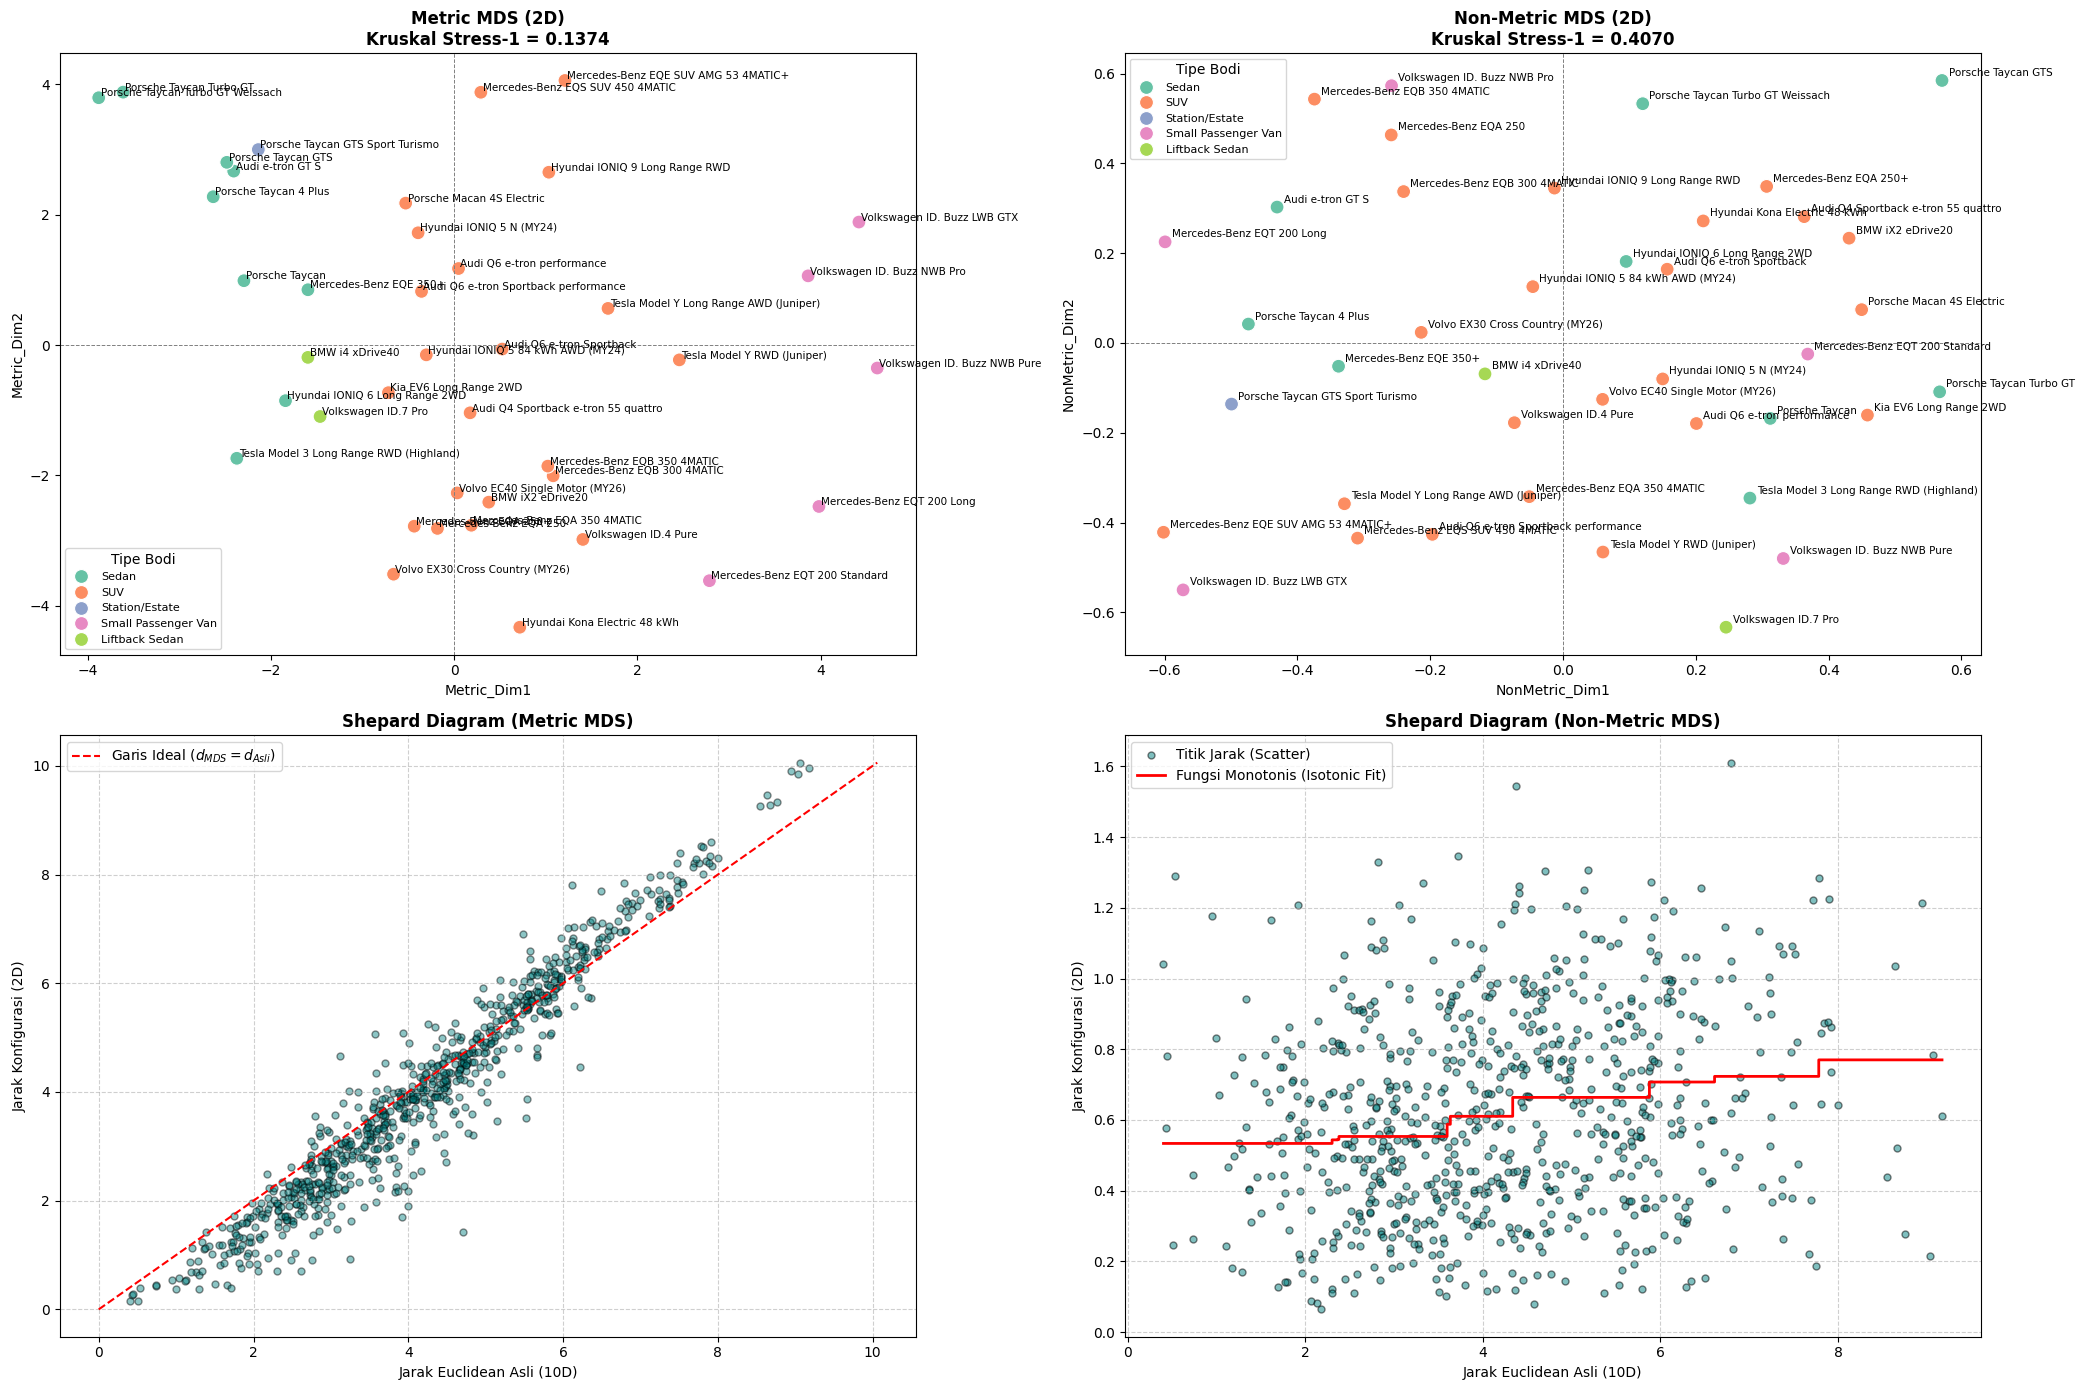

In [ ]:
iu = np.triu_indices(len(dist_matrix), k=1)
d_asli = dist_matrix[iu]
d_hat_metric = euclidean_distances(coords_metric)[iu]
d_konfigurasi_nonmetric = euclidean_distances(coords_nonmetric)[iu]

# Isotonic regression untuk Shepard Diagram Non-Metric MDS
isotonic = IsotonicRegression(increasing=True)
d_monoton = isotonic.fit_transform(d_asli, d_konfigurasi_nonmetric)
sort_idx = np.argsort(d_asli)
d_asli_sorted = d_asli[sort_idx]
d_monoton_sorted = d_monoton[sort_idx]

fig, axes = plt.subplots(2, 2, figsize=(21, 14))
axes = axes.flatten()

# Plot 1: Metric MDS Map
sns.scatterplot(data=df_sample, x='Metric_Dim1', y='Metric_Dim2', hue='car_body_type', s=100, palette='Set2', ax=axes[0])
for i in range(len(df_sample)):
    axes[0].text(df_sample['Metric_Dim1'][i]+0.02, df_sample['Metric_Dim2'][i]+0.02, df_sample['car_label'][i], fontsize=7.5)
axes[0].axhline(0, color='grey', ls='--', lw=0.7)
axes[0].axvline(0, color='grey', ls='--', lw=0.7)
axes[0].set_title(f'Metric MDS (2D)\nKruskal Stress-1 = {stress1_metric:.4f}', fontweight='bold')
axes[0].legend(title='Tipe Bodi', fontsize=8)

# Plot 2: Non-Metric MDS Map
sns.scatterplot(data=df_sample, x='NonMetric_Dim1', y='NonMetric_Dim2', hue='car_body_type', s=100, palette='Set2', ax=axes[1])
for i in range(len(df_sample)):
    axes[1].text(df_sample['NonMetric_Dim1'][i]+0.01, df_sample['NonMetric_Dim2'][i]+0.01, df_sample['car_label'][i], fontsize=7.5)
axes[1].axhline(0, color='grey', ls='--', lw=0.7)
axes[1].axvline(0, color='grey', ls='--', lw=0.7)
axes[1].set_title(f'Non-Metric MDS (2D)\nKruskal Stress-1 = {stress1_nonmetric:.4f}', fontweight='bold')
axes[1].legend(title='Tipe Bodi', fontsize=8)

# Plot 3: Shepard Plot (Metric MDS) - Fixed 7D -> 10D
axes[2].scatter(d_asli, d_hat_metric, alpha=0.45, color='teal', edgecolors='k', s=25)
max_d = max(d_asli.max(), d_hat_metric.max())
axes[2].plot([0, max_d], [0, max_d], 'r--', lw=1.5, label='Garis Ideal ($d_{MDS} = d_{Asli}$)')
axes[2].set_title('Shepard Diagram (Metric MDS)', fontweight='bold')
axes[2].set_xlabel('Jarak Euclidean Asli (10D)')
axes[2].set_ylabel('Jarak Konfigurasi (2D)')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.6)

# Plot 4: Shepard Plot (Non-Metric MDS)
axes[3].scatter(d_asli, d_konfigurasi_nonmetric, alpha=0.5, color='teal', edgecolors='k', s=25, label='Titik Jarak (Scatter)')
axes[3].step(d_asli_sorted, d_monoton_sorted, color='red', where='post', lw=2, label='Fungsi Monotonis (Isotonic Fit)')
axes[3].set_title('Shepard Diagram (Non-Metric MDS)', fontweight='bold')
axes[3].set_xlabel('Jarak Euclidean Asli (10D)')
axes[3].set_ylabel('Jarak Konfigurasi (2D)')
axes[3].legend(loc='upper left')
axes[3].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()